# Lab 2: Baseline Model Training and Evaluation

## Data Preprocessing Decisions:
1. **Duplicates:** 4281 duplicate rows (28.5%) were found and **dropped** to prevent data leakage and overfitting.
2. **Missing values:** 0 (no imputation needed).
3. **Feature selection:** `attack_cat` was excluded from features (X) to prevent target leakage, as it directly reveals the `label`.
4. **Categorical encoding:** `proto`, `service`, `state` will be One-Hot Encoded.
5. **Scaling:** Numerical features will be standardized using `StandardScaler`.

In [1]:

import json
import hashlib
from pathlib import Path

import matplotlib
matplotlib.use('Agg')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path('../data/dataset.csv')
METRICS_DIR = Path('../metrics')
METRICS_DIR.mkdir(exist_ok=True)

print("Setup complete")


Setup complete


In [2]:

# 1. Load data
df = pd.read_csv(DATA_PATH)
print(f"Original shape: {df.shape}")

# 2. Drop duplicates (CRITICAL STEP)
initial_len = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after dropping {initial_len - len(df)} duplicates: {df.shape}")

# 3. Separate features and target
# Drop 'attack_cat' to avoid target leakage, drop 'label' as it is the target
X = df.drop(columns=['label', 'attack_cat'])
y = df['label']

print(f"Features shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts(normalize=True).round(4)}")

# 4. Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train label distribution:\n{y_train.value_counts(normalize=True).round(4)}")


Original shape: (15000, 36)


Shape after dropping 4281 duplicates: (10719, 36)
Features shape: (10719, 34)
Target distribution:
label
0    0.574
1    0.426
Name: proportion, dtype: float64

Train shape: (8575, 34), Test shape: (2144, 34)
Train label distribution:
label
0    0.574
1    0.426
Name: proportion, dtype: float64


In [3]:

# Identify categorical and numerical columns
categorical_cols = ['proto', 'service', 'state']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

print(f"Categorical columns: {categorical_cols}")
print(f"Numerical columns count: {len(numerical_cols)}")

# Create preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ])

# Create full pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced'))
])

print("Pipeline created successfully")


Categorical columns: ['proto', 'service', 'state']
Numerical columns count: 31
Pipeline created successfully


In [4]:

# Train the model
print("Training Logistic Regression...")
pipeline.fit(X_train, y_train)

# Predict
y_pred = pipeline.predict(X_test)

# Calculate metrics
metrics = {
    'accuracy': round(accuracy_score(y_test, y_pred), 4),
    'precision_macro': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
    'recall_macro': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 4),
    'f1_macro': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4),
    'f1_weighted': round(f1_score(y_test, y_pred, average='weighted', zero_division=0), 4),
    'test_size': len(y_test)
}

print("\n=== Model Metrics ===")
for k, v in metrics.items():
    print(f"{k}: {v}")

# Save metrics to JSON
with open(METRICS_DIR / 'baseline.json', 'w') as f:
    json.dump(metrics, f, indent=4)
print("\n✓ Metrics saved to metrics/baseline.json")

# Classification report
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Attack (1)']))


Training Logistic Regression...


=== Model Metrics ===
accuracy: 0.7794
precision_macro: 0.7755
recall_macro: 0.7803
f1_macro: 0.7767
f1_weighted: 0.7803
test_size: 2144

✓ Metrics saved to metrics/baseline.json

=== Classification Report ===
              precision    recall  f1-score   support

  Normal (0)       0.83      0.77      0.80      1231
  Attack (1)       0.72      0.79      0.75       913

    accuracy                           0.78      2144
   macro avg       0.78      0.78      0.78      2144
weighted avg       0.78      0.78      0.78      2144



✓ Confusion matrix saved to ../metrics/confusion_matrix.png


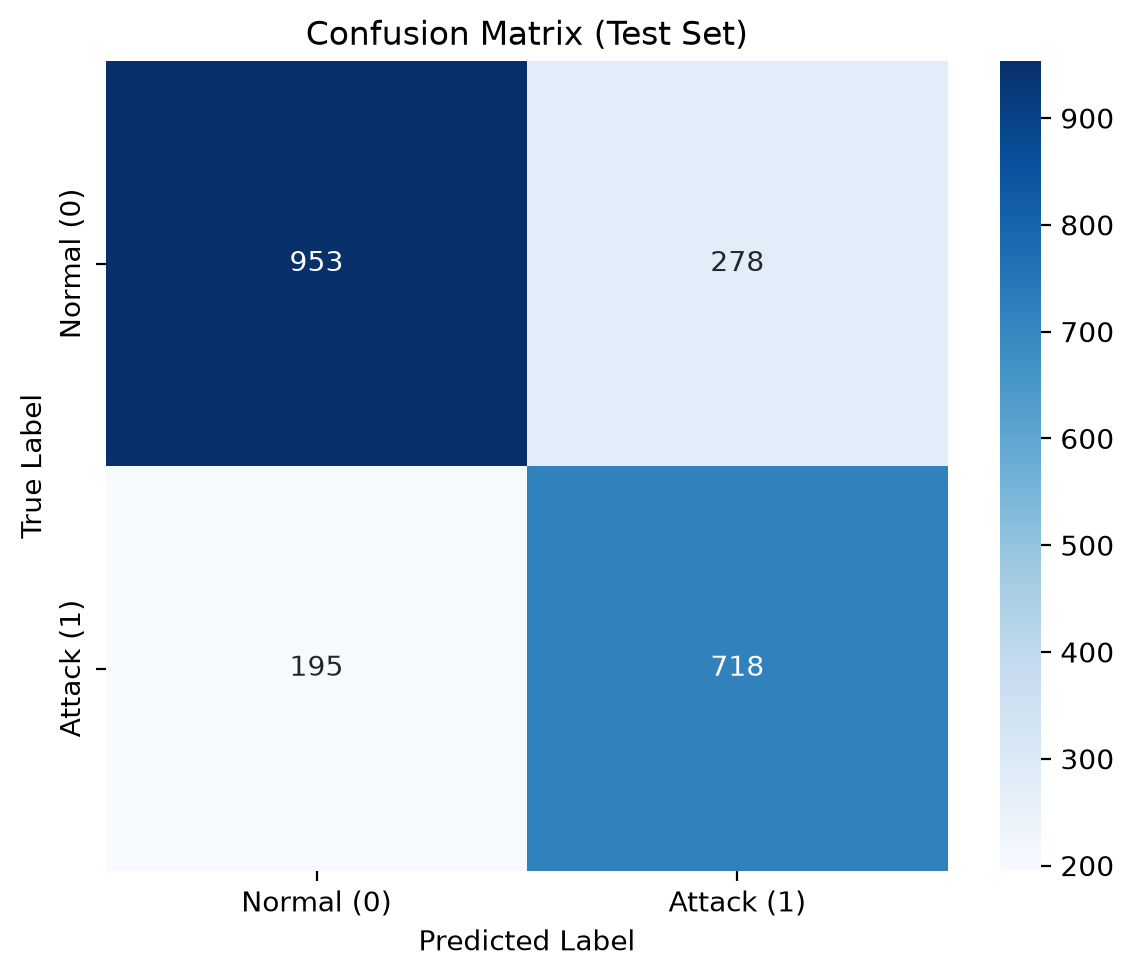

In [5]:

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal (0)', 'Attack (1)'], 
            yticklabels=['Normal (0)', 'Attack (1)'])
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()

cm_path = METRICS_DIR / 'confusion_matrix.png'
plt.savefig(cm_path, dpi=200, bbox_inches='tight')
print(f"✓ Confusion matrix saved to {cm_path}")

# Display in notebook
from IPython.display import Image, display
display(Image(filename=str(cm_path)))
